In [15]:
import dotenv 

In [16]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [17]:

os.environ['GROQ_API_KEY']=os.getenv('GROQ_API_KEY')

In [18]:

os.environ['TAVILY_API_KEY']=os.getenv('TAVILY_API_KEY')

os.environ['LANGCHAIN_API_KEY']=os.getenv('LANGCHAIN_API_KEY')




In [19]:
from langchain.chat_models import init_chat_model
llm= init_chat_model(model="openai/gpt-oss-120b",model_provider='groq')

In [20]:
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

In [21]:
api_wrapper_arxiv= ArxivAPIWrapper(top_k_results=2,doc_content_chars_max=500)
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv)

print(arxiv.name)

arxiv


In [22]:
import arxiv
from langchain_community.utilities import ArxivAPIWrapper
from langchain_community.tools import ArxivQueryRun

# Fix for AttributeError: 'Search' object has no attribute 'results'
arxiv.Search.results = lambda self, *args, **kwargs: arxiv.Client().results(self, *args, **kwargs)

# Tool initialize karein
arxiv_tool = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())

# Search run karein
response = arxiv_tool.invoke("Attention is all you need")
print(response)

Published: 2021-05-06
Title: Do You Even Need Attention? A Stack of Feed-Forward Layers Does Surprisingly Well on ImageNet
Authors: Luke Melas-Kyriazi
Summary: The strong performance of vision transformers on image classification and other vision tasks is often attributed to the design of their multi-head attention layers. However, the extent to which attention is responsible for this strong performance remains unclear. In this short report, we ask: is the attention layer even necessary? Specifically, we replace the attention layer in a vision transformer with a feed-forward layer applied over the patch dimension. The resulting architecture is simply a series of feed-forward layers applied over the patch and feature dimensions in an alternating fashion. In experiments on ImageNet, this architecture performs surprisingly well: a ViT/DeiT-base-sized model obtains 74.9\% top-1 accuracy, compared to 77.9\% and 79.9\% for ViT and DeiT respectively. These results indicate that aspects of vis

In [23]:
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper
from langchain_community.tools import WikipediaQueryRun, ArxivQueryRun

# 1. Wikipedia Tool
api_wrapper_wiki = WikipediaAPIWrapper(top_k_results=2, doc_content_chars_max=500)
wiki = WikipediaQueryRun(api_wrapper=api_wrapper_wiki)


# Check names
print(wiki.name)   # Output: wikipedia


wikipedia


In [24]:

from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.tools import WikipediaQueryRun

api_wrapper_wiki = WikipediaAPIWrapper(
    top_k_results=2,
    doc_content_chars_max=500)

wiki = WikipediaQueryRun(
    api_wrapper=api_wrapper_wiki)

result = wiki.invoke("What is Deep Learning?")

print(result)

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [26]:
# tavily tool

In [27]:
from langchain_community.tools.tavily_search import TavilySearchResults
tavily= TavilySearchResults()

C:\Users\hpvic\AppData\Local\Temp\ipykernel_4956\3527437817.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily= TavilySearchResults()


In [28]:
tavily.invoke('provide recent ai news nov 2026')

[{'title': 'Latest AI News | 5th Nov 2026 (EST) | Apple Cuts AI Budget, Microsoft Walks Away and AI PACs Spend B',
  'url': 'https://www.youtube.com/watch?v=OyLJLtug_lo',
  'content': "Today's top AI news: Apple reportedly slashes internal AI spending, Microsoft walks away from a $170 billion AI deal, AI PACs spent millions on the midterms, Nothing teases an AI-first device, OpenAI reveals a plan for responsible AI infrastructure, and more. We break down what each story means for you — no jargon, just the facts. Plus, we cover the AI market rotation and Arm's stock drop. Stay informed on the AI boom and how it affects your job, your phone, and your wallet. Subscribe for daily AI news in plain English!\n\n━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━\n🔔 SUBSCRIBE for daily AI & tech news — new video every day!\n👍 LIKE if you found this helpful!\n💬 COMMENT your thoughts or questions below!\n🔔 Hit the notification bell so you never miss an update! [...] [0:47] What this means for you, soon the A

In [29]:
# combine all tool in list

In [30]:
tool=[arxiv_tool,wiki,tavily]

In [31]:
from langchain.messages import AIMessage,HumanMessage,SystemMessage, AnyMessage

In [32]:
llm_with_tool=llm.bind_tools(tool)

llm_with_tool.invoke([HumanMessage(content='what is llm model')])

AIMessage(content='**Large Language Model (LLM)**  \n\nA **large language model (LLM)** is a type of artificial‑intelligence system that learns to generate, understand, and manipulate natural‑language text (and, increasingly, other modalities such as code, images, or audio) by training on massive corpora of data.  \n\nBelow is a concise yet comprehensive overview covering what an LLM is, how it works, why it’s “large,” its typical architectures, training pipelines, capabilities, limitations, and common examples.\n\n---\n\n## 1. Core Definition  \n\n- **Language model**: A probabilistic model that assigns a likelihood\u202f\\(P(\\text{sentence})\\)\u202fto any sequence of tokens (words, sub‑words, characters). It can also predict the next token given a context, i.e.,\u202f\\(P(w_{t} \\mid w_{1},\\dots,w_{t-1})\\).  \n- **Large**: Refers to two related dimensions:  \n  1. **Scale of parameters** – usually from hundreds of millions to trillions of trainable weights.  \n  2. **Scale of tra

In [33]:
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages

In [34]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain.messages import AnyMessage
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

In [35]:
from langgraph.graph import StateGraph,END,START

from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


In [36]:
def multiply(a:int,b:int)->int:
    """Multiply a and b 
    Args:
        a first int
        b second int
    """
    return a*b
def add(a:int,b:int)->int:
    """Addition a and b 
    Args:
        a first int
        b second int
    """
    return a+b
def divide(a:int,b:int)->int:
    """Divide a and b 
    Args:
        a first int
        b second int
    """
    return a/b

In [37]:
tool=[arxiv_tool,wiki,tavily,add,multiply,divide]

In [38]:
#Node 
def tool_call_llm(state:State):
    return {'messages':[llm_with_tool.invoke(state['messages'])]}

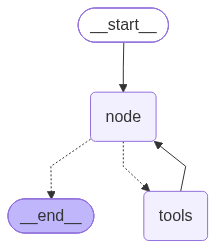

In [39]:
graph = StateGraph(State)


graph.add_node('node', tool_call_llm)
graph.add_node('tools', ToolNode(tool))


graph.add_edge(START, 'node')

graph.add_conditional_edges('node', tools_condition)


graph.add_edge('tools', 'node')


graph.compile()

In [40]:
graph.compile().invoke({'messages':HumanMessage(content='what is machine learning')})

{'messages': [HumanMessage(content='what is machine learning', additional_kwargs={}, response_metadata={}, id='8fea5aef-11d3-4f0a-94fd-029cfd9beb84'),
  AIMessage(content='**Machine learning (ML)** is a subfield of artificial intelligence that focuses on developing algorithms and statistical models that enable computers to **learn from data** and improve their performance on a specific task without being explicitly programmed for every possible scenario.\n\n### Core Ideas\n| Concept | Description |\n|---------|-------------|\n| **Learning from Data** | Algorithms infer patterns, relationships, or rules from examples (training data). |\n| **Generalization** | The goal is to perform well on new, unseen data (test data), not just memorizing the training set. |\n| **Prediction / Decision‑making** | Once trained, models can make predictions, classify inputs, generate content, control systems, etc. |\n| **Iterative Improvement** | Models can be refined continuously as more data becomes avail

In [41]:
for m in graph.compile().invoke({'messages':HumanMessage(content='who is narendra modi what is  2 plus 2')})['messages']:
    m.pretty_print()

================================ Human Message =================================

who is narendra modi what is  2 plus 2
================================== Ai Message ==================================
Tool Calls:
  wikipedia (fc_4c038293-add3-44c6-b464-333a4f60a9d2)
 Call ID: fc_4c038293-add3-44c6-b464-333a4f60a9d2
  Args:
    query: Narendra Modi
================================= Tool Message =================================
Name: wikipedia

Page: Narendra Modi
Summary: Narendra Damodardas Modi (born 17 September 1950) is an Indian politician who has served as the  prime minister of India since 26 May 2014. Modi was the chief minister of Gujarat from 2001 to 2014 and is the Member of Parliament (MP) for Varanasi. He is a member of the Bharatiya Janata Party (BJP) and of the Rashtriya Swayamsevak Sangh (RSS), a right-wing Hindutva paramilitary volunteer organisation. He is India's third-longest-serving prime minister, and the longest
================================== Ai Message ====

In [42]:


# memory saver

In [43]:
from langgraph.checkpoint.memory  import MemorySaver

memory= MemorySaver()

In [44]:
graph_memory= graph.compile(checkpointer=memory)

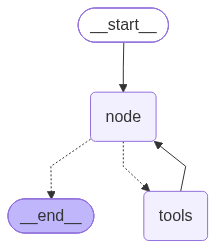

In [45]:
graph_memory

In [46]:
config={'configurable':{'thread_id':"1"}}

In [47]:
for m in graph.compile(checkpointer=memory).invoke({'messages':HumanMessage(content='who is narendra modi what is  2 plus 2')},config=config)['messages']:
    m.pretty_print()

================================ Human Message =================================

who is narendra modi what is  2 plus 2
================================== Ai Message ==================================

**Narendra Modi**

Narendra Modi is the 14th Prime Minister of India. He has been in office since May 2014, after leading the Bharatiya Janata Party (BJP) to a decisive victory in the 2014 general election and winning a second term in 2019. Before becoming prime minister, Modi served as the Chief Minister of the Indian state of Gujarat from 2001 to 2014. His tenure has been marked by a focus on economic reforms (such as the Goods and Services Tax and the “Make in India” initiative), large‑scale infrastructure projects, a strong emphasis on digital services, and a nationalist political agenda. He is a highly polarizing figure, praised by supporters for his development drive and criticized by opponents for policies they view as divisive.

**2 plus 2**

\(2 + 2 = 4\).


In [48]:
for m in graph.compile(checkpointer=memory).invoke({'messages':HumanMessage(content='what i asked last time')},config=config)['messages']:
    m.pretty_print()

================================ Human Message =================================

who is narendra modi what is  2 plus 2
================================== Ai Message ==================================

**Narendra Modi**

Narendra Modi is the 14th Prime Minister of India. He has been in office since May 2014, after leading the Bharatiya Janata Party (BJP) to a decisive victory in the 2014 general election and winning a second term in 2019. Before becoming prime minister, Modi served as the Chief Minister of the Indian state of Gujarat from 2001 to 2014. His tenure has been marked by a focus on economic reforms (such as the Goods and Services Tax and the “Make in India” initiative), large‑scale infrastructure projects, a strong emphasis on digital services, and a nationalist political agenda. He is a highly polarizing figure, praised by supporters for his development drive and criticized by opponents for policies they view as divisive.

**2 plus 2**

\(2 + 2 = 4\).
=====================

In [ ]:
graph_builder=graph.compile(checkpointer=memory)
config={'configurable':{'thread_id':"2"}}
for m in graph_builder.stream({'messages':HumanMessage(content='who is narendra modi what is  2 plus 2')},config=config,stream_mode='updates'):
    print(m['node'])

NameError: name 'graph' is not defined

In [ ]:
graph_builder=graph.compile(checkpointer=memory)
config={'configurable':{'thread_id':"2"}}
for m in graph_builder.stream({'messages':HumanMessage(content='forget everything')},config=config,stream_mode='values'):
    print(m)

{'messages': [HumanMessage(content='who is narendra modi what is  2 plus 2', additional_kwargs={}, response_metadata={}, id='a053270f-b886-4f88-9ee0-ce38fe7b8ede'), AIMessage(content='**Narendra\u202fModi**  \nNarendra\u202fModi is the current Prime Minister of India, having first taken office on\u202f26\u202fMay\u202f2014. He is a member of the Bharatiya Janata Party (BJP) and previously served as the Chief Minister of the Indian state of Gujarat from 2001 to 2014. Under his leadership, the Indian government has pursued initiatives such as “Digital India,” “Make in India,” and the rollout of the Goods and Services Tax (GST). Modi is a prominent figure in both Indian and global politics.\n\n**2\u202f+\u202f2**  \n\\(2 + 2 = 4\\).', additional_kwargs={'reasoning_content': 'The user asks: "who is narendra Modi what is 2 plus 2". They want two pieces: a brief description of Narendra Modi, and answer to 2+2 = 4. Provide concise answer. No need external tools.'}, response_metadata={'token_u

In [ ]:
graph_builder=graph.compile(checkpointer=memory)
config={'configurable':{'thread_id':"3"}}
async for m in graph_builder.astream_events({'messages':HumanMessage(content='forget everything')},config=config):
    print(m)

{'event': 'on_chain_start', 'data': {'input': {'messages': HumanMessage(content='forget everything', additional_kwargs={}, response_metadata={})}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1e9ef-4d2d-7172-94cf-71fb2e70ba97', 'metadata': {'thread_id': '3', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='forget everything', additional_kwargs={}, response_metadata={}, id='00169f38-1d60-4ef3-bfd9-27c83317f20f')]}}, 'name': 'node', 'tags': ['graph:step:1'], 'run_id': '01a1e9ef-4d30-7be2-be8d-6ec19283fea4', 'metadata': {'thread_id': '3', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'node', 'langgraph_triggers': ('branch:to:node',), 'langgraph_path': ('__pregel_pull', 'node'), 'langgraph_checkpoint_ns': 'node:5be96810-8001-cfc7-282b-df32722f3395'}, 'parent_ids': ['01a1e9ef-4d2d-7172-94cf-71fb2e70ba97']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[HumanMessag